# Digital Archeology of ATP Match Histories
**Team:** Phouvadeth Vathana, Joseph Bronyah, Dhrumil Patel

This executed full-study notebook uses the same modules and configuration as the CLI. Study years are 2000–2024, with 1990–1999 as history warm-up. The three questions concern subsequent recorded performance after ranking upsets, previous meetings as predictors, and opponent handedness. Conclusions are observational; “recovery” is not a psychological measurement.

Install dependencies from the repository root with `python -m pip install -r requirements.txt`. For reproducible fresh-kernel execution, run `python execute_notebook.py`.

In [1]:
from pathlib import Path
import json
import logging
import pandas as pd
from IPython.display import display, Markdown, Image
from tennis_project import Config, run_project
from tennis_repro import verify_output
from tennis_reporting import generate_reports
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
assert Path("tennis_project.py").exists(), "Run from the repository root."


## Full study versus demonstration
`RUN_FULL_STUDY = True` uses the pinned, hash-checked cache offline and publishes the authoritative full run to `outputs_final`. If required inputs are missing, run the online CLI command from README first. The demo branch uses a separate output directory and never replaces full-study reports.

Ranking upset: a top-50 player loses to someone ranked at least 30 places lower. Age and experience remain separate; experience means earlier eligible history observed since 1990.

In [2]:
RUN_FULL_STUDY = True
config = Config(history_start=1990, analysis_start=2000, end_year=2024, test_start=2020,
                upset_max_rank=50, upset_rank_gap=30, min_hand_matches=10,
                bootstrap_samples=500, random_seed=42, offline=True, output_dir="outputs_final")
input_files = None
if not RUN_FULL_STUDY:
    config.history_start = config.analysis_start = config.end_year = 2024
    config.output_dir = "validation/notebook_demo"
    input_files = [Path("tests/fixtures/brisbane_2024_excerpt.csv")]
    print("DEMONSTRATION ONLY: 31 real source records; not research findings.")
summary = run_project(config, input_files=input_files)
output = Path(config.output_dir)
verify_output(output)
print("Run ID:", summary["run_id"])
print("Raw records:", summary["raw_match_rows"])
print("Eligible physical study matches:", summary["eligible_analysis_matches"])
print("Input files:", len(summary["inputs"]))
for q in ["q1", "q2", "q3"]:
    print(q.upper(), summary[q]["status"])


INFO: Loaded 112056 raw match rows from 35 file(s).


INFO: Verified run 20261027T121134Z-20f069d1 saved in /Users/dhrumil/Fall 2026/FDA/tennis_final_project/outputs_final


Run ID: 20261027T121134Z-20f069d1
Raw records: 112056
Eligible physical study matches: 63784
Input files: 35
Q1 Q1 descriptive tables and exploratory adjusted recovery-rate regression fitted; conditional associations with dependence limitations.
Q2 Chronological Q2 comparison fitted: baseline, +meeting count, +head-to-head results.
Q3 Q3 within-player adjusted model fitted with explicit inference warnings.


In [3]:
if RUN_FULL_STUDY:
    verified, answers = generate_reports(output)
    assert verified["run_id"] == summary["run_id"]
else:
    answers = ["Demo only: no full-study finding is inferred."] * 3
print("Actual environment:")
display(pd.DataFrame(summary["runtime"].items(), columns=["package", "version"]))
print("Base code revision:", summary["code"]["revision"], "Dirty:", summary["code"]["dirty"])


Actual environment:


,package,version
0,python,3.13.7
1,platform,macOS-26.6.2-arm64-arm-64bit-Mach-O
2,numpy,2.5.4
3,pandas,2.3.3
4,scipy,1.18.1
5,scikit_learn,1.9.1
6,statsmodels,0.14.6
7,matplotlib,3.11.2
8,requests,2.34.2
9,pytest,9.1.1


Base code revision: 27f3cdca880281396badef197949aaa75008313f Dirty: True


## Data quality before interpretation
Player-perspective rows are dependent views, not additional independent matches. Attrition flow counts use a first-reason rule; overlapping flags are reported separately. Missing or conflicting event records remain auditable blockers. Tournament-week dates and checked knockout rounds approximate chronology; exact match dates and days to recovery are not claimed.

In [4]:
display(pd.read_csv(output / "attrition.csv"))
display(pd.read_csv(output / "exclusion_flow.csv"))
display(pd.read_csv(output / "chronology_checks.csv"))
display(pd.read_csv(output / "coverage_by_year.csv"))
print("Overlapping exclusion flags:", summary["exclusion_flag_counts_nonexclusive"])


,stage,count,unit,population,note
0,raw_records,112056,source_rows,all_input_files,NaN
1,exact_duplicates_removed,0,source_rows,all_input_files,NaN
2,warmup_records,37150,deduplicated_source_rows,history,NaN
3,study_period_records,74906,deduplicated_source_rows,study,NaN
4,study_unique_match_keys,74906,distinct_source_match_keys,study,Conflicting keys are unresolved physical match...
5,study_resolved_unique_physical_matches,74906,physical_matches,study,NaN
6,study_eligible_matches,63784,physical_matches,study,NaN
7,study_player_perspective_rows,149812,player_views,study,Includes excluded records retained for follow-...
8,study_eligible_player_perspective_rows,127568,player_views,study,NaN
9,q1_all_eligible_index_losses,63784,loss_events,Q1,NaN


,period,first_reason,records
0,study,ambiguous_order,938
1,study,eligible,63784
2,study,outside_individual_AMG_scope,7780
3,study,unfinished_or_unrecognized_score,2404
4,warmup,ambiguous_order,318
5,warmup,eligible,32717
6,warmup,outside_individual_AMG_scope,3327
7,warmup,unfinished_or_unrecognized_score,788


,check,records_or_keys
0,unreliable_order_records,12385
1,invalid_identity_records,0
2,missing_dates,0
3,conflicting_source_rows,0
4,conflicting_match_keys,0
5,same_date_multiple_events,4
6,repeated_player_round,9804
7,unsupported_round_event,12384
8,missing_tournament_date,0


,season,source_matches,eligible_matches,unknown_winner_hands,unknown_loser_hands
0,1990,3743,3301,35,88
1,1991,3727,3286,38,83
2,1992,3730,3322,36,60
3,1993,3890,3477,22,54
4,1994,3938,3516,21,54
5,1995,3800,3356,23,46
6,1996,3836,3340,13,56
7,1997,3561,3103,14,41
8,1998,3591,3129,15,49
9,1999,3334,2887,15,51


Overlapping exclusion flags: {'invalid_player_ids': 0, 'conflicting_match_key': 0, 'outside_individual_AMG_scope': 11107, 'unfinished_or_unrecognized_score': 3505, 'ambiguous_order': 12385, 'outside_history_window': 0, 'missing_match_key': 0}


In [5]:
missing = pd.read_csv(output / "missingness_by_group.csv")
display(missing.loc[missing.dimension.eq("player_hand")])
display(pd.read_csv(output / "spotcheck_evidence.csv"))
print(summary["spot_checks"]["scope"])


,dimension,group,field,player_views,missing,missing_percent
210,player_hand,L,player_rank,19119,169,0.883937
211,player_hand,L,opponent_rank,19119,181,0.946702
212,player_hand,L,player_age,19119,0,0.000000
213,player_hand,L,recent_win_rate,19119,586,3.065014
214,player_hand,L,service_win_rate,19119,1273,6.658298
215,player_hand,L,player_hand,19119,0,0.000000
216,player_hand,L,opponent_hand,19119,90,0.470736
217,player_hand,R,player_rank,129629,1269,0.978948
218,player_hand,R,opponent_rank,129629,1547,1.193406
219,player_hand,R,player_age,129629,0,0.000000


,kind,player_id,match_id,evidence,expected,observed,passed
0,history_count,103819,1998-314:2,atp_matches_1998.csv: CSV row 2032,0.000000,0.000000,True
1,source_outcome,103819,1998-314:2,atp_matches_1998.csv: CSV row 2032,0.000000,0.000000,True
2,history_count,103819,2009-451:16,atp_matches_2009.csv: CSV row 1562,678.000000,678.000000,True
3,source_outcome,103819,2009-451:16,atp_matches_2009.csv: CSV row 1562,1.000000,1.000000,True
4,history_count,103819,2021-540:223,atp_matches_2021.csv: CSV row 1677,1356.000000,1356.000000,True
5,source_outcome,103819,2021-540:223,atp_matches_2021.csv: CSV row 1677,0.000000,0.000000,True
6,history_count,104745,2002-573:6,atp_matches_2002.csv: CSV row 2502,0.000000,0.000000,True
7,source_outcome,104745,2002-573:6,atp_matches_2002.csv: CSV row 2502,1.000000,1.000000,True
8,history_count,104745,2012-451:1,atp_matches_2012.csv: CSV row 60,589.000000,589.000000,True
9,source_outcome,104745,2012-451:1,atp_matches_2012.csv: CSV row 60,1.000000,1.000000,True


Automated local source/history consistency only; no independent external verification or human review.


## Q1 — Subsequent performance after ranking upsets
Both descriptive and adjusted comparisons use known-rank losses by top-50 players. Missing follow-up remains missing, never zero wins. Age and observed experience are separately summarized and jointly included with upset interactions. Adjusted contrasts condition on subsequent opponents and playing context, so they describe conditional associations. Player-clustered intervals account for repeated and overlapping windows within players; the sensitivity greedily retains windows with no reused index/follow-up matches.

In [6]:
display(Markdown(answers[0]))
display(pd.read_csv(output / "q1_summary_overall.csv"))
display(pd.read_csv(output / "q1_summary_age.csv"))
display(pd.read_csv(output / "q1_summary_experience.csv"))
display(pd.read_csv(output / "q1_followup_status.csv"))


After a ranking upset, adjusted next-three-match performance differed from ordinary losses by -1.37 pp (95% interval -2.24 to -0.51 pp) across 18,471 complete, covariate-usable loss events from 341 players. The next-match difference was -1.46 pp (95% interval -2.84 to -0.07 pp). Age modification was +0.03 pp (95% interval -0.29 to +0.35 pp) per year; experience modification was +1.08 pp (95% interval -0.50 to +2.66 pp) per unit of log(1 + prior matches). For age, the interval includes zero; for experience, the interval includes zero. Interpret the joint age and experience interactions using their intervals, rather than treating descriptive age bands as experience groups. Adjustment includes subsequent playing context, so this is a conditional association, not a causal recovery effect.

,loss_type,index_losses,unique_players,usable_next_matches,complete_three_match_windows,incomplete_or_unusable_windows,mean_age,median_age,mean_prior_matches,median_prior_matches,next_match_win_rate,next_match_ci95_lower,next_match_ci95_upper,next_match_players,next_three_win_rate,next_three_ci95_lower,next_three_ci95_upper,next_three_players
0,other_ranked_loss,16485,339,14550,12661,3824,26.687461,26.5,300.464786,255.0,0.625430,0.608237,0.642622,338,0.597373,0.582267,0.612478,335
1,ranking_upset,7536,326,6695,5885,1651,26.720104,26.4,308.570196,263.5,0.619716,0.601680,0.637753,321,0.593826,0.577545,0.610107,317


,loss_type,age_group,index_losses,unique_players,usable_next_matches,complete_three_match_windows,incomplete_or_unusable_windows,mean_age,median_age,mean_prior_matches,median_prior_matches,next_match_win_rate,next_match_ci95_lower,next_match_ci95_upper,next_match_players,next_three_win_rate,next_three_ci95_lower,next_three_ci95_upper,next_three_players
0,other_ranked_loss,under_23,2790,128,2431,2099,691,21.380287,21.7,113.080287,100.0,0.635130,0.608888,0.661371,127,0.624107,0.599550,0.648663,124
1,other_ranked_loss,23_to_29,10372,301,9125,7949,2423,26.345131,26.3,277.166699,254.0,0.631781,0.612662,0.650899,300,0.602424,0.586015,0.618833,298
2,other_ranked_loss,30_plus,3323,133,2994,2613,710,32.211887,31.7,530.513091,523.0,0.598196,0.567303,0.629089,131,0.560531,0.534667,0.586394,128
3,ranking_upset,under_23,1223,122,1070,936,287,21.470155,21.7,124.970564,112.0,0.661682,0.628065,0.695300,120,0.632123,0.602681,0.661564,118
4,ranking_upset,23_to_29,4794,285,4225,3715,1079,26.285774,26.2,282.439925,259.0,0.621538,0.600661,0.642415,279,0.591386,0.572952,0.609821,276
5,ranking_upset,30_plus,1519,127,1400,1234,285,32.317775,31.7,538.860434,535.0,0.582143,0.548014,0.616271,126,0.572123,0.541872,0.602375,125


,loss_type,experience_group,index_losses,unique_players,usable_next_matches,complete_three_match_windows,incomplete_or_unusable_windows,mean_age,median_age,mean_prior_matches,median_prior_matches,next_match_win_rate,next_match_ci95_lower,next_match_ci95_upper,next_match_players,next_three_win_rate,next_three_ci95_lower,next_three_ci95_upper,next_three_players
0,other_ranked_loss,under_100,2504,232,2254,1971,533,22.941693,22.5,66.854233,68.5,0.543478,0.520628,0.566329,230,0.525960,0.506691,0.545229,225
1,other_ranked_loss,100_to_299,7128,250,6286,5465,1663,25.375561,25.1,194.790544,194.0,0.618995,0.599265,0.638725,248,0.593535,0.577544,0.609525,247
2,other_ranked_loss,300_plus,6853,158,6010,5225,1628,29.420662,29.2,495.737925,457.0,0.662895,0.637719,0.688071,157,0.628325,0.605970,0.650681,157
3,ranking_upset,under_100,993,205,887,789,204,23.074119,22.8,67.934542,70.0,0.510710,0.472050,0.549371,198,0.505703,0.476916,0.534491,191
4,ranking_upset,100_to_299,3268,237,2889,2540,728,25.171695,24.8,196.799266,197.0,0.626514,0.603628,0.649401,231,0.587402,0.568336,0.606467,228
5,ranking_upset,300_plus,3275,156,2919,2556,719,29.370687,29.1,493.064427,453.0,0.646112,0.620945,0.671279,155,0.627413,0.605912,0.648913,153


,loss_type,followup_status,index_losses,players
0,other_ranked_loss,complete,12661,335
1,other_ranked_loss,fewer_than_three_recorded_followups,56,41
2,other_ranked_loss,followup_contains_excluded_or_ambiguous_match,3768,293
3,ranking_upset,complete,5885,317
4,ranking_upset,fewer_than_three_recorded_followups,21,19
5,ranking_upset,followup_contains_excluded_or_ambiguous_match,1630,268


In [7]:
q1 = pd.read_csv(output / "q1_adjusted_contrasts.csv")
display(q1.loc[q1.subgroup.eq("all")])
display(pd.read_csv(output / "q1_model_samples.csv"))
display(pd.read_csv(output / "q1_threshold_sensitivity.csv"))


,outcome,sample,contrast,subgroup,events,players,subgroup_players,estimate_pp,standard_error_pp,ci95_lower_pp,ci95_upper_pp,inference_status
0,next3_win_rate,all_windows,average_upset_minus_ordinary,all,18471,341,341,-1.374741,0.439090,-2.238417,-0.511066,available
7,next3_win_rate,all_windows,age_interaction_per_year,all,18471,341,341,0.027307,0.163685,-0.294655,0.349269,available
8,next3_win_rate,all_windows,experience_interaction_log_unit,all,18471,341,341,1.079881,0.801013,-0.495684,2.655446,available
9,next3_win_rate,nonoverlapping,average_upset_minus_ordinary,all,9684,341,341,-1.620825,0.633101,-2.866113,-0.375537,available
16,next3_win_rate,nonoverlapping,age_interaction_per_year,all,9684,341,341,-0.079397,0.216255,-0.504764,0.345969,available
17,next3_win_rate,nonoverlapping,experience_interaction_log_unit,all,9684,341,341,1.275633,1.071690,-0.832345,3.383610,available
18,next1_win,all_windows,average_upset_minus_ordinary,all,21206,345,345,-1.459569,0.703985,-2.844227,-0.074912,available
25,next1_win,all_windows,age_interaction_per_year,all,21206,345,345,-0.496558,0.269418,-1.026472,0.033356,available
26,next1_win,all_windows,experience_interaction_log_unit,all,21206,345,345,2.238648,1.342995,-0.402868,4.880163,available
27,next1_win,nonoverlapping,average_upset_minus_ordinary,all,16263,345,345,-1.744492,0.832843,-3.382597,-0.106388,available


,outcome,sample,available_windows,excluded_missing_covariates,model_events,model_players,status,design_columns,design_rank,formula
0,next3_win_rate,all_windows,18546,75,18471,341,fitted,40,40,next3_win_rate ~ ranking_upset * (age_centered...
1,next3_win_rate,nonoverlapping,9723,39,9684,341,fitted,40,40,next3_win_rate ~ ranking_upset * (age_centered...
2,next1_win,all_windows,21245,39,21206,345,fitted,40,40,next1_win ~ ranking_upset * (age_centered + lo...
3,next1_win,nonoverlapping,16295,32,16263,345,fitted,40,40,next1_win ~ ranking_upset * (age_centered + lo...


,rank_gap_threshold,loss_type,age_group,index_losses,players,complete_windows,next_match_win_rate,next_three_win_rate
0,20,other_ranked_loss,under_23,2454,127,1841,0.634112,0.621582
1,20,other_ranked_loss,23_to_29,9077,299,6955,0.630168,0.601150
2,20,other_ranked_loss,30_plus,2955,133,2324,0.603145,0.563253
3,20,ranking_upset,under_23,1559,123,1194,0.657605,0.634283
4,20,ranking_upset,23_to_29,6089,289,4709,0.626118,0.595597
5,20,ranking_upset,30_plus,1887,127,1523,0.577481,0.565769
6,30,other_ranked_loss,under_23,2790,128,2099,0.635130,0.624107
7,30,other_ranked_loss,23_to_29,10372,301,7949,0.631781,0.602424
8,30,other_ranked_loss,30_plus,3323,133,2613,0.598196,0.560531
9,30,ranking_upset,under_23,1223,122,936,0.661682,0.632123


## Q2 — Previous meetings and prediction
Exactly one outcome-independent orientation per physical match enters prediction. All three models use the same chronological test matches, training-only preprocessing and frozen parameters. Earlier test results can update later histories: this is as-of-match evaluation, not one forecast made at the beginning of 2020. Shared meeting count alone does not favor either player. Positive paired improvement means lower Brier/log loss or higher accuracy; pair-cluster intervals leave some cross-pair dependence unresolved.

In [8]:
display(Markdown(answers[1]))
for name in ["q2_model_metrics.csv", "q2_paired_improvements.csv", "q2_calibration.csv"]:
    path = output / name
    if path.exists():
        display(pd.read_csv(path))
    else:
        print(name, "unavailable for this sample")


On 11,340 held-out matches, meeting count alone changed Brier performance by -0.000021 (95% interval -0.000091 to +0.000039); the interval includes zero. Adding previous head-to-head results changed Brier performance by +0.000586 (95% interval +0.000095 to +0.001019). Positive improvement means lower prediction error; for previous results, the interval is above zero. Meeting count and previous outcomes answer different questions. Pair-cluster intervals leave shared-player dependence across pairs unresolved.

,model,meeting_group,test_matches,brier_score,log_loss,accuracy
0,baseline,all,11340,0.216957,0.622392,0.646561
1,baseline,0,6460,0.218058,0.624868,0.644737
2,baseline,1,2345,0.216520,0.620514,0.640512
3,baseline,2_to_4,2027,0.215390,0.619963,0.653182
4,baseline,5_plus,508,0.211233,0.609274,0.671260
5,plus_meeting_count,all,11340,0.216979,0.622421,0.647531
6,plus_meeting_count,0,6460,0.218059,0.624826,0.645666
7,plus_meeting_count,1,2345,0.216478,0.620425,0.642217
8,plus_meeting_count,2_to_4,2027,0.215443,0.620110,0.654662
9,plus_meeting_count,5_plus,508,0.211680,0.610274,0.667323


,first_model,second_model,metric,test_matches,mean_improvement,ci95_lower,ci95_upper,pair_clusters,resamples,limitation,mean_brier_improvement,status
0,baseline,plus_meeting_count,brier,11340,-0.000021,-0.000091,0.000039,7824,500,Pair-cluster resampling does not capture every...,-0.000021,Computed
1,baseline,plus_meeting_count,log_loss,11340,-0.000028,-0.000217,0.000121,7824,500,Pair-cluster resampling does not capture every...,NaN,Computed
2,baseline,plus_meeting_count,accuracy,11340,0.000970,-0.000177,0.002298,7824,500,Pair-cluster resampling does not capture every...,NaN,Computed
3,baseline,plus_h2h_results,brier,11340,0.000586,0.000095,0.001019,7824,500,Pair-cluster resampling does not capture every...,0.000586,Computed
4,baseline,plus_h2h_results,log_loss,11340,0.001422,0.000342,0.002391,7824,500,Pair-cluster resampling does not capture every...,NaN,Computed
5,baseline,plus_h2h_results,accuracy,11340,0.001587,-0.001555,0.004945,7824,500,Pair-cluster resampling does not capture every...,NaN,Computed
6,plus_meeting_count,plus_h2h_results,brier,11340,0.000607,0.000113,0.001039,7824,500,Pair-cluster resampling does not capture every...,0.000607,Computed
7,plus_meeting_count,plus_h2h_results,log_loss,11340,0.001451,0.000338,0.002411,7824,500,Pair-cluster resampling does not capture every...,NaN,Computed
8,plus_meeting_count,plus_h2h_results,accuracy,11340,0.000617,-0.002334,0.003870,7824,500,Pair-cluster resampling does not capture every...,NaN,Computed


,model,probability_bin,bin_lower,bin_upper,matches,mean_prediction,observed_win_rate
0,baseline,0,0.0,0.1,113,0.075416,0.097345
1,baseline,1,0.1,0.2,828,0.159521,0.195652
2,baseline,2,0.2,0.3,1380,0.253314,0.284783
3,baseline,3,0.3,0.4,1745,0.350159,0.370201
4,baseline,4,0.4,0.5,1967,0.450076,0.455008
5,baseline,5,0.5,0.6,1835,0.548485,0.525341
6,baseline,6,0.6,0.7,1538,0.647832,0.609233
7,baseline,7,0.7,0.8,1141,0.747531,0.724803
8,baseline,8,0.8,0.9,676,0.841829,0.849112
9,baseline,9,0.9,1.0,117,0.923693,0.888889


## Q3 — Opponent handedness
Unadjusted within-player service summaries use valid integer point totals and explicit opportunity minima. They are separate from adjusted match-result contrasts. The adjusted model absorbs player fixed effects and uses shared-player dyadic covariance. Right- and left-handed focal-player contrasts use the full covariance, including the interaction cross term. Legacy covariance failures remain visible; inference is not made valid merely by fitting a model.

In [9]:
display(Markdown(answers[2]))
for name in ["q3_descriptive_contrasts.csv", "q3_adjusted_contrasts.csv", "q3_subgroup_support.csv", "q3_inference_sensitivity.csv"]:
    path = output / name
    if path.exists():
        display(pd.read_csv(path))
    else:
        print(name, "unavailable for this sample")
influence = output / "q3_player_influence.csv"
if influence.exists():
    display(pd.read_csv(influence))


Adjusted opponent-left-minus-right win-probability differences were +1.11 pp (95% interval -0.86 to +3.08 pp) for 365 right-handed focal players and +0.99 pp (95% interval -0.63 to +2.62 pp) for 55 left-handed focal players. For right-handed players, the interval includes zero; for left-handed players, the interval includes zero. The results do not establish a uniform handedness advantage. Dyadic intervals account for matches sharing either participant; the smaller left-handed subgroup and remaining event/network dependence warrant caution.

,player_hand,players,matches_vs_L,matches_vs_R,mean_player_win_difference_pp,median_player_win_difference_pp,service_eligible_players,mean_player_service_difference_pp,service_points_vs_L,service_points_vs_R,interpretation
0,L,56,1890,12759,1.672411,2.217873,56,-0.126322,149398.0,1025885.0,Unadjusted equal-player means; service differe...
1,R,371,13219,86506,3.444849,3.658179,370,0.869144,1058530.0,6961834.0,Unadjusted equal-player means; service differe...


,method,player_hand,contrast,players,player_match_rows,unique_matches,coefficient,variance,standard_error,ci95_lower,ci95_upper,difference_pp,standard_error_pp,ci95_lower_pp,ci95_upper_pp,inference_status
0,dyadic_primary,R,opponent_L_minus_R,365,98104,59339,0.011106,0.000101,0.010048,-0.008587,0.030799,1.110637,1.004763,-0.858662,3.079936,available
1,dyadic_primary,L,opponent_L_minus_R,55,14399,13585,0.009934,0.000069,0.008291,-0.006315,0.026184,0.993414,0.829065,-0.631524,2.618352,available


,sample,player_hand,opponent_hand,player_match_rows,unique_matches,players,opponents,opponent_pairs,tournaments,largest_player_share,top5_player_share
0,known_hand_descriptive,L,L,2162,1081,138,138,646,685,0.060130,0.244218
1,known_hand_descriptive,L,R,14579,14579,197,859,8257,1575,0.072502,0.263667
2,known_hand_descriptive,R,L,14579,14579,859,197,8257,1575,0.010632,0.048014
3,known_hand_descriptive,R,R,96118,48059,1302,1302,26156,1585,0.012193,0.048503
4,adjusted,L,L,1850,1036,55,120,602,663,0.069189,0.282162
5,adjusted,L,R,12549,12549,55,760,6423,1554,0.084150,0.304168
6,adjusted,R,L,13001,13001,365,173,6802,1568,0.011922,0.053688
7,adjusted,R,R,85103,46338,365,1052,24605,1585,0.013701,0.054416


,method,player_hand,contrast,players,player_match_rows,unique_matches,coefficient,variance,standard_error,ci95_lower,ci95_upper,difference_pp,standard_error_pp,ci95_lower_pp,ci95_upper_pp,inference_status
0,legacy_player_match,R,opponent_L_minus_R,365,98104,59339,0.011106,0.000018,0.004243,0.002791,0.019422,1.110637,0.424285,0.279053,1.942220,available
1,legacy_player_match,L,opponent_L_minus_R,55,14399,13585,0.009934,0.000004,0.001872,0.006265,0.013603,0.993414,0.187183,0.626543,1.360286,available
2,tournament_only,R,opponent_L_minus_R,365,98104,59339,0.011106,0.000016,0.004010,0.003247,0.018966,1.110637,0.400985,0.324721,1.896553,available
3,tournament_only,L,opponent_L_minus_R,55,14399,13585,0.009934,0.000034,0.005854,-0.001540,0.021408,0.993414,0.585402,-0.153953,2.140782,available
4,single_hash_view_player_cluster,R,opponent_L_minus_R,237,42229,42229,0.004295,0.000044,0.006600,-0.008640,0.017230,0.429512,0.659964,-0.863994,1.723019,available
5,single_hash_view_player_cluster,L,opponent_L_minus_R,34,6151,6151,0.013735,0.000143,0.011946,-0.009679,0.037149,1.373524,1.194605,-0.967859,3.714906,available


,excluded_player_id,excluded_player_hand,excluded_focal_rows,player_hand,remaining_players,remaining_unique_matches,remaining_player_match_rows,sample,difference_pp,identified,interpretation
0,104745,L,1180,R,409,60138,109408,drop_player_as_either_participant_reapply_oppo...,2.057460,True,Point-estimate sensitivity; removes all select...
1,104745,L,1180,L,409,60138,109408,drop_player_as_either_participant_reapply_oppo...,1.680614,True,Point-estimate sensitivity; removes all select...
2,104269,L,945,R,409,60370,109825,drop_player_as_either_participant_reapply_oppo...,1.242863,True,Point-estimate sensitivity; removes all select...
3,104269,L,945,L,409,60370,109825,drop_player_as_either_participant_reapply_oppo...,1.242725,True,Point-estimate sensitivity; removes all select...
4,103852,L,928,R,411,60409,110092,drop_player_as_either_participant_reapply_oppo...,1.195618,True,Point-estimate sensitivity; removes all select...
5,103852,L,928,L,411,60409,110092,drop_player_as_either_participant_reapply_oppo...,1.158644,True,Point-estimate sensitivity; removes all select...
6,103813,L,655,R,412,60685,110620,drop_player_as_either_participant_reapply_oppo...,1.163525,True,Point-estimate sensitivity; removes all select...
7,103813,L,655,L,412,60685,110620,drop_player_as_either_participant_reapply_oppo...,1.169552,True,Point-estimate sensitivity; removes all select...
8,105173,L,611,R,403,60588,110026,drop_player_as_either_participant_reapply_oppo...,1.027376,True,Point-estimate sensitivity; removes all select...
9,105173,L,611,L,403,60588,110026,drop_player_as_either_participant_reapply_oppo...,0.902634,True,Point-estimate sensitivity; removes all select...


## Charts
Labels distinguish unadjusted descriptions from adjusted probability differences. Intervals are displayed only when estimable. Calibration-bin rates are descriptive; denominators are in the calibration table.

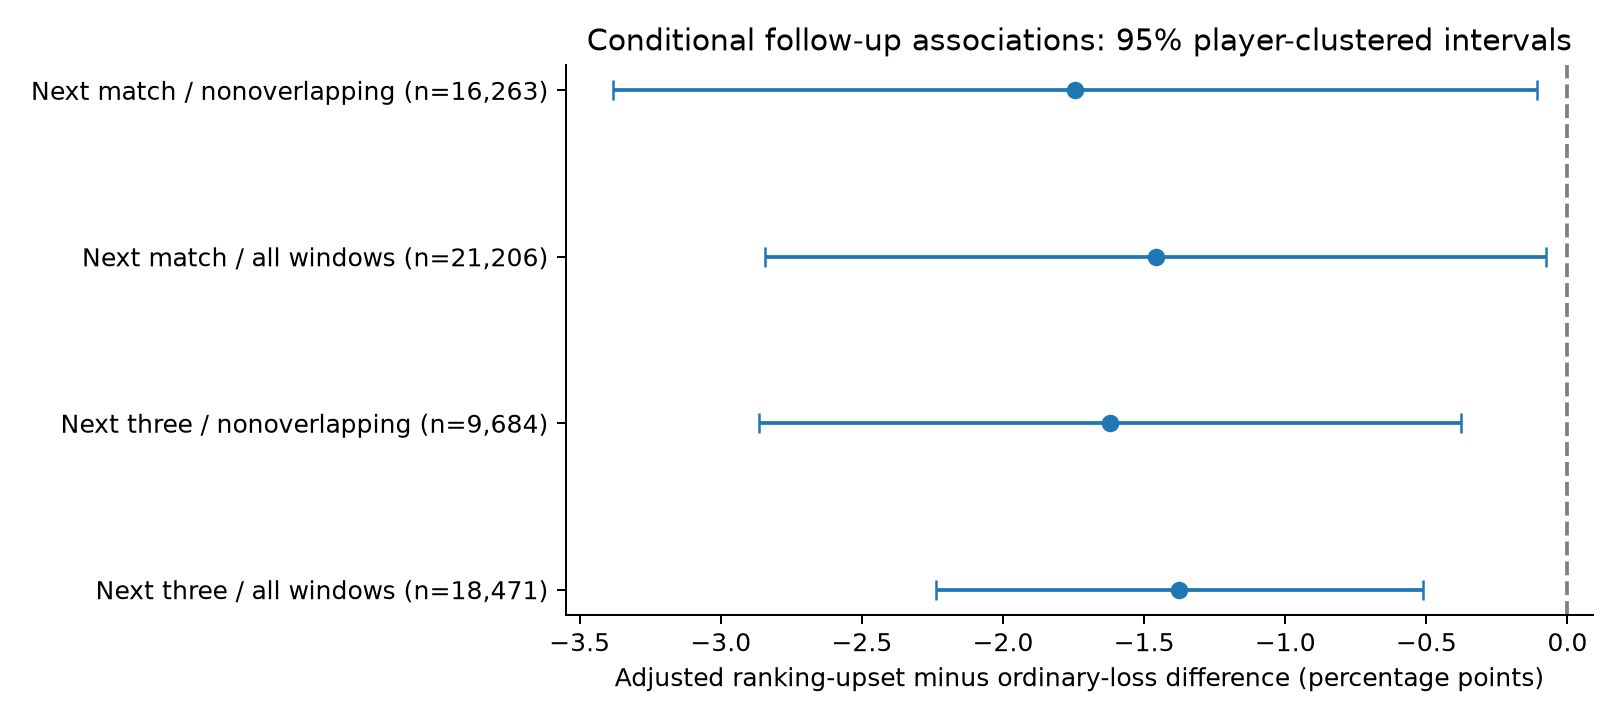

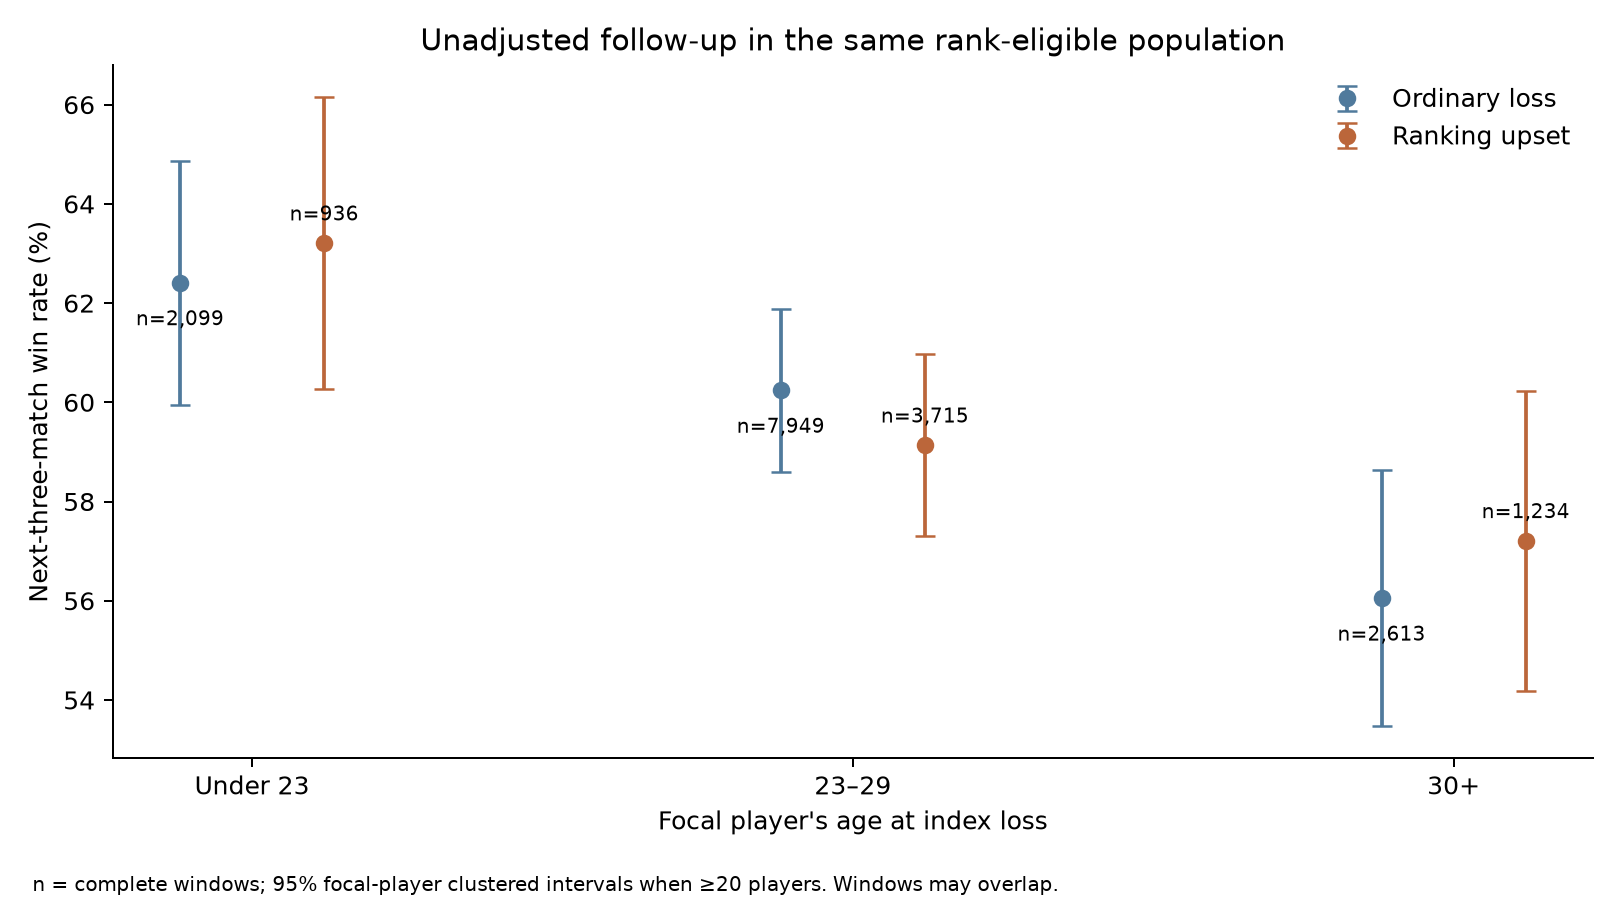

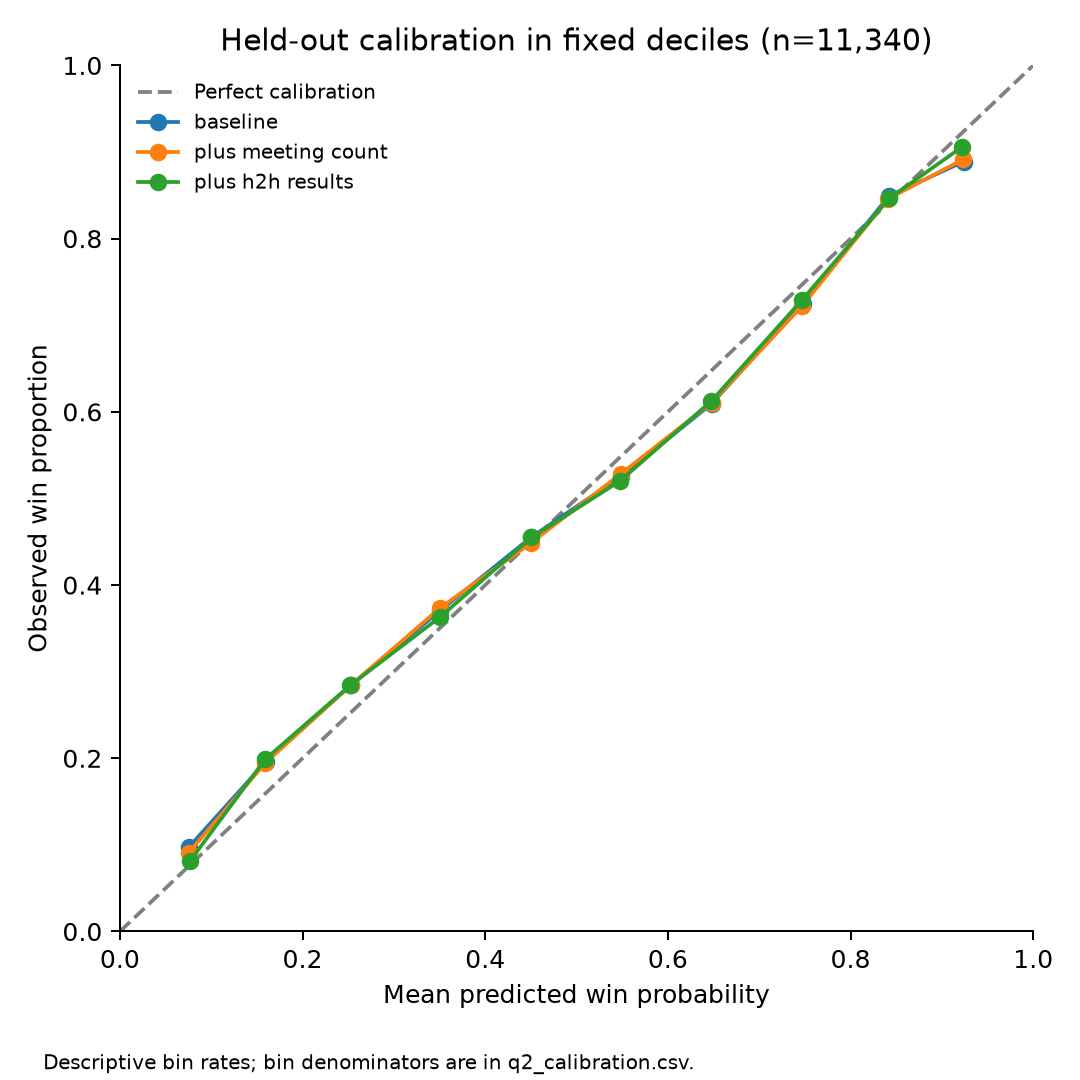

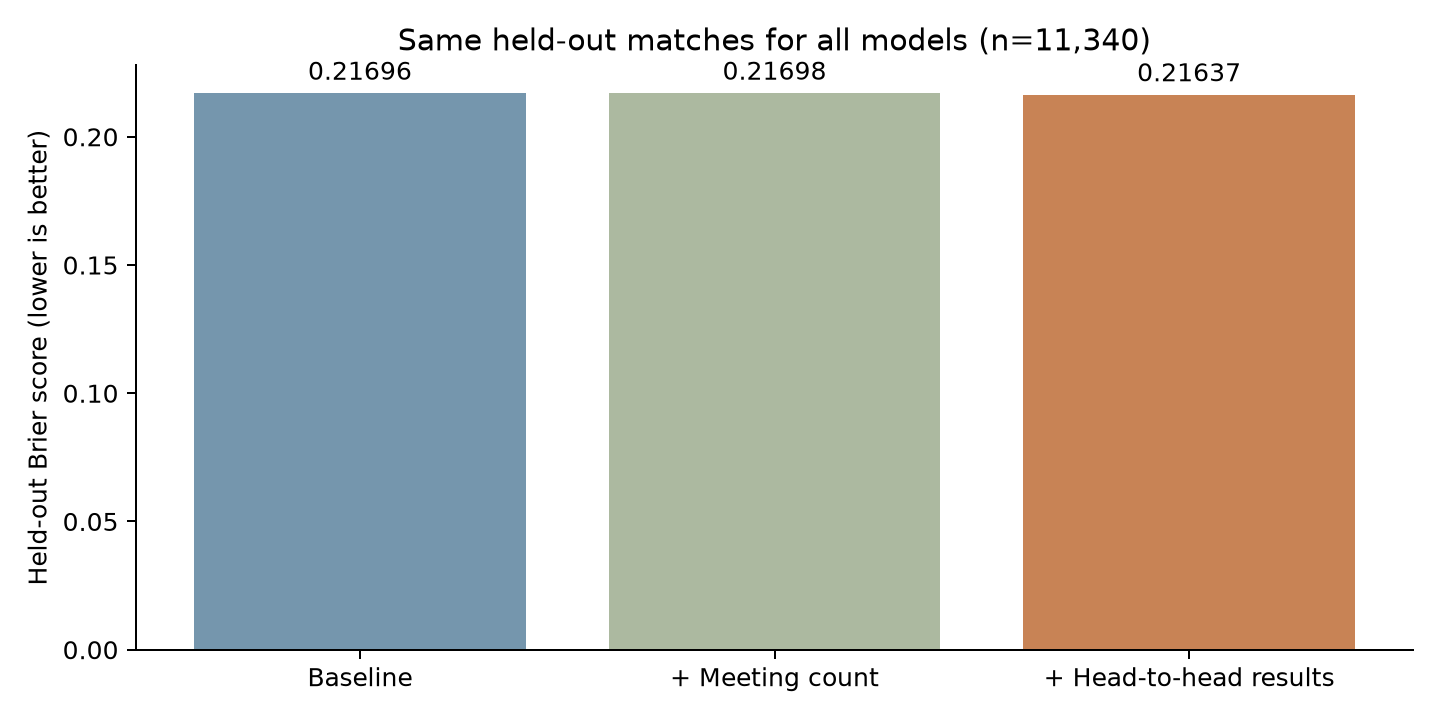

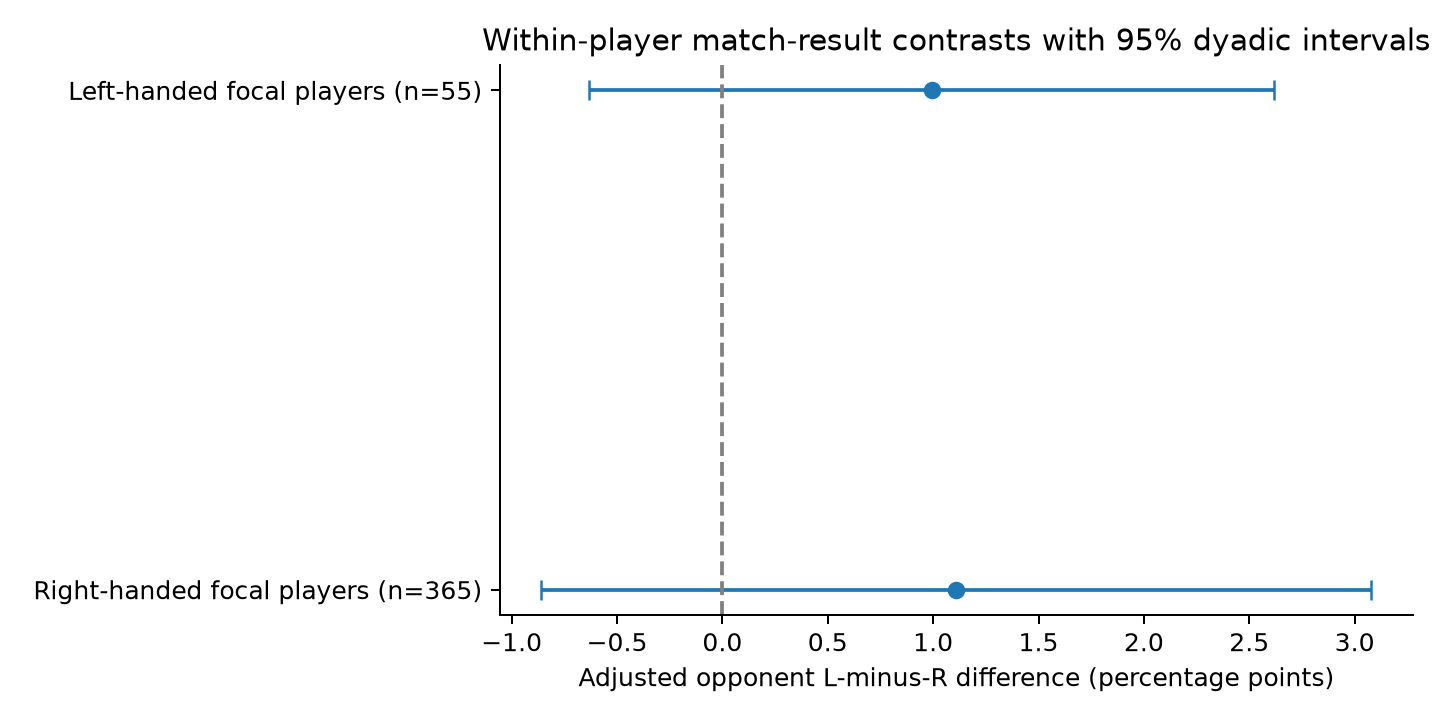

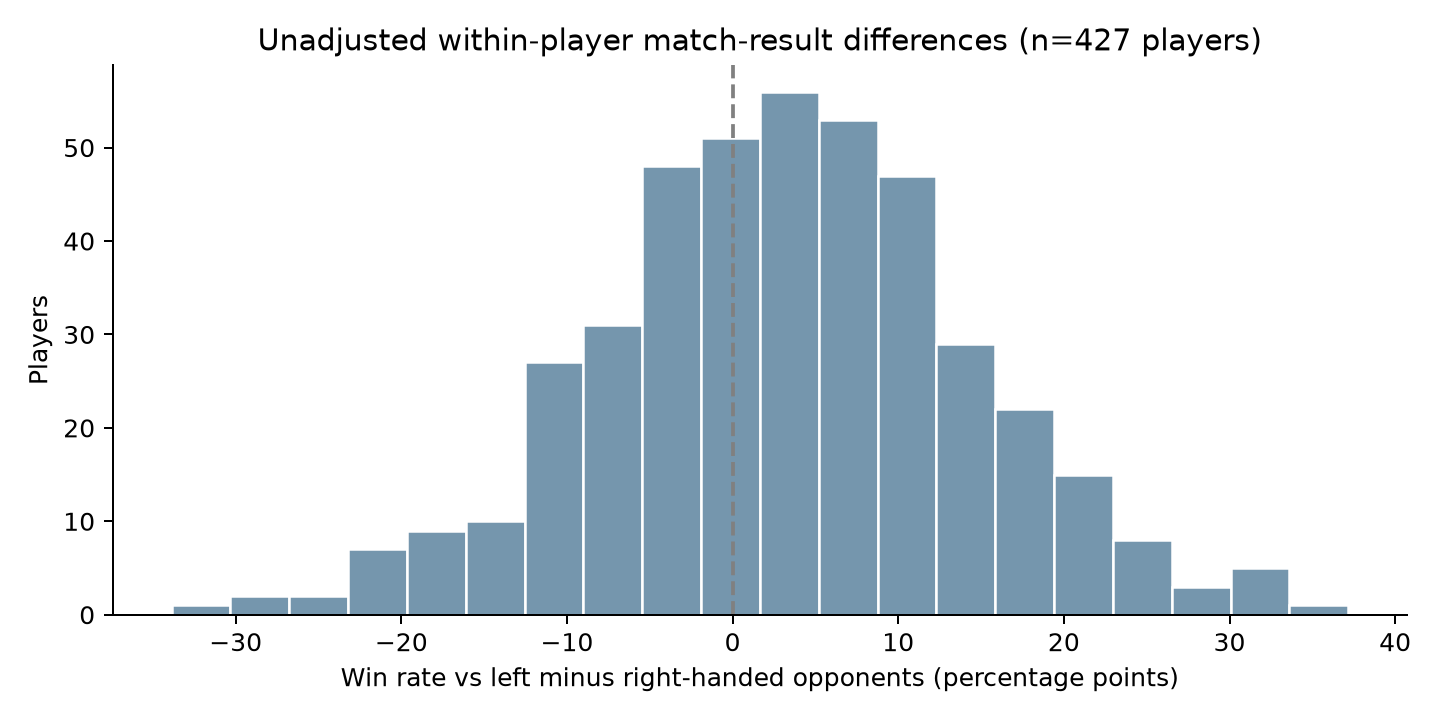

In [10]:
for path in sorted((output / "charts").glob("*.png")):
    display(Image(filename=str(path)))


## Warnings, reproducibility and final report
Source data were compiled by Jeff Sackmann and obtained from the pinned Aneeshers archive. Source/derived data and code have separate licenses. This notebook performs automated local consistency checks; it does not claim external verification or human review. Missing source matches, coarse chronology, selection, model assumptions and residual dependence limit conclusions. See `reports/FINAL_REPORT.md`, `reports/RESULTS.md`, `reports/DATA_QUALITY.md`, `SOURCES.md` and `TEST_RESULTS.md`.

In [11]:
for question in ["q1", "q2", "q3"]:
    print(question.upper(), summary[question].get("analysis_status", summary[question]["status_code"]))
    for warning in summary[question]["warnings"]:
        print(" -", warning)
print("Runtime warnings:", summary["runtime_warnings"])
verify_output(output)
if RUN_FULL_STUDY:
    claims = json.loads(Path("reports/report_claims.json").read_text())
    assert claims["run_id"] == summary["run_id"]
    assert summary["run_id"] in Path("README.md").read_text()
    print("Notebook, README, report and summary share run", summary["run_id"])


Q1 fitted_with_limitations
 - Follow-up context adjustment estimates a conditional association; focal-player clustering does not cover all shared-opponent dependence.
Q2 fitted_with_limitations
 - Paired intervals cluster opponent pairs; shared-player dependence across pairs remains.
Q3 fitted_with_warnings
 - Legacy player-by-match covariance has negative coefficient variance(s); affected intervals are unavailable. Primary dyadic covariance clusters through either participant.
 - Dyadic intervals assume no residual dependence between disjoint player pairs; tournament-wide shocks and indirect network dependence may remain. Tournament-only sensitivity does not address serial player dependence.
 - Left-handed subgroup support is smaller; asymptotic intervals and the exposure-based deletion checks do not establish uniform effects across players.
Runtime warnings: [{'category': 'DeprecationWarning', 'message': "The 'generic' unit for NumPy timedelta is deprecated, and will raise an error i

Notebook, README, report and summary share run 20261027T121134Z-20f069d1
